In [ ]:
"""Cell 2: Imports e setup do ambiente."""

from __future__ import annotations

import sys
from pathlib import Path

import nest_asyncio
import numpy as np  # noqa: F401

# ── Detecta raiz do projeto e adiciona src/ ao path ANTES dos imports do pacote ──
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
project_root = None
for p in candidates:
    if (p / "src" / "radioskysims").exists() and (p / "settings.toml").exists():
        project_root = p
        break

if project_root is None:
    msg = "Raiz do projeto não encontrada."
    raise RuntimeError(msg)

src_path = str((project_root / "src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# ── Imports do projeto (após configurar sys.path) ──
from radioskysims.application.services.sim_orchestrator import SimOrchestrator

nest_asyncio.apply()

In [2]:
# ── Repositório: load / flush (descarta o item corrente) / delete(by_id) ──
# Registra no banco apontando para o arquivo persistido (Zarr) e testa o ciclo de vida.
# ── Orquestrador BINGO ──
orch = SimOrchestrator.from_settings("bingo")

repo = orch.simulation_repository


In [4]:
loaded = repo.load(15)
comp_result = loaded  # SimulationOrchestratorResult

In [5]:
ds_orch = comp_result.simulation_result.dataset
tr = comp_result.simulation_result.time_range
fr = comp_result.simulation_result.freq_range

In [6]:
ds_orch

<xarray.Dataset> Size: 1GB
Dimensions:           (time: 145, frequency: 381, polarization: 4, source: 311,
                       pointing: 1)
Coordinates:
  * pointing          (pointing) int64 8B 0
  * frequency         (frequency) float64 3kB 9.8e+08 9.81e+08 ... 1.36e+09
    source_type       (source) <U11 14kB ...
  * polarization      (polarization) <U7 112B 'H_COPOL' 'H_CROSS' ... 'V_CROSS'
  * time              (time) datetime64[ns] 1kB 2026-07-26 ... 2026-07-27
    pointing_alt_deg  (pointing) float64 8B ...
    pointing_az_deg   (pointing) float64 8B ...
    angle_boresight   (pointing, source, time) float64 361kB ...
  * source            (source) <U22 27kB 'GPS BIIR-11 (PRN 19)' ... '125952+0...
Data variables:
    T_antenna         (time, frequency, polarization, source, pointing) float64 550MB ...
    power             (time, frequency, polarization, source, pointing) float64 550MB ...
Attributes: (12/15)
    description:              Time-Ordered Data
    contributions:            satellite
    backend:                  ideal
    polarization_handling:    unpolarized
    time_start:               2026-07-26T00:00:00.000
    time_end:                 2026-07-27T00:00:00.000
    ...                       ...
    fwhm_factor:              3.0
    beam_fwhm_threshold_deg:  36.87132352941177
    radioskysim_provenance:   {"created_at": "2026-08-04T17:10:35.601427+00:0...
    freq_min_mhz:             980.0
    freq_max_mhz:             1360.0
    freq_resolution_mhz:      1.0

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
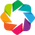

🌐 Waterfall TOD interativo em: http://localhost:5007   (para encerrar: stop_waterfall_servers())


Launching server at http://localhost:5007


ERROR:bokeh.server.protocol_handler:error handling message
 message: Message 'PATCH-DOC' content: {'events': [{'kind': 'ModelChanged', 'model': {'id': '870ac305-9196-4490-9e44-38c70c2dcefa'}, 'attr': 'value_throttled', 'new': 0}]} 
 error: UnknownReferenceError("can't resolve reference '870ac305-9196-4490-9e44-38c70c2dcefa'")
Traceback (most recent call last):
  File "/media/barosi/RadioSkySim/.venv/lib/python3.13/site-packages/bokeh/server/protocol_handler.py", line 94, in handle
    work = await handler(message, connection)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/media/barosi/RadioSkySim/.venv/lib/python3.13/site-packages/bokeh/server/session.py", line 94, in _needs_document_lock_wrapper
    result = func(self, *args, **kwargs)
  File "/media/barosi/RadioSkySim/.venv/lib/python3.13/site-packages/bokeh/server/session.py", line 286, in _handle_patch
    message.apply_to_document(self.document, self)
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/media/barosi

In [ ]:
try:
    from radioskysims.visualization import serve_tod_panel, stop_waterfall_servers

    # Encerra sessões/servidores anteriores para evitar referências órfãs no Bokeh
    try:
        stop_waterfall_servers()
    except Exception:
        pass

    prev_server = globals().get("server")
    if prev_server is not None:
        try:
            prev_server.stop()
        except Exception:
            pass

    # Eventos não são persistidos no repositório; recomputa sob demanda a partir do dataset.
    events = comp_result.events

    # Painel interativo (abra no navegador; render de widget no VS Code costuma falhar).
    url, server = serve_tod_panel(
        ds_orch,
        events=events,
        port=5007,
        title="Waterfall TOD interativo",
        width=1200,
        height=350,
        cmap="inferno",
        use_datashader=True,
        time_range=tr,
    )

    print(f"🌐 Abra no navegador: {url}")

except ImportError as e:
    print(f"⚠️  {e}")
    print("Instale com: pip install holoviews datashader")
except Exception as e:
    import traceback

    traceback.print_exc()
    print(f"⚠️  Erro ao gerar visualização: {e}")
    print("(se persistir, reinicie o kernel e execute as células em ordem)")